# QPDK flipmon test chip — 4 flip-chip circular transmons on a U-shaped probeline (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/flipmon_test_chip.pic.yml` (the `.py`
only loads it), with `qpdk/cells/derived/transmon_with_resonator_and_probeline.py`
(`flipmon_with_resonator_and_probeline`) and `qpdk/cells/transmon.py` (`flipmon_with_bbox`),
<https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024; depth-1 clone read
2026-11-03, never executed). Spec: `docs/designs/qpdk/flipmon_test_chip.md`. Reference: Li et al. 2021,
vacuum-gap transmon qubits. It is the [qubit test chip](qubit_test_chip.ipynb) netlist line for line, with the
qubit cell replaced by the flip-chip "flipmon" and resonator lengths 5000 / 4800 / 4600 / 4400 µm; every coupled
section uses QPDK's automatic length (800 µm), so the probeline U-turn moves 400 µm east (x = 3815 µm).

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 4.25 × 6.2 mm chip area | the 7.5 × 7.5 mm Quantcore die (`QP.die_box(4250, 6200)`), Quantcore die frame on the bottom chip, device ID "QPDK-FTC"; the top chip (face 2b1) gets no frame (PDK v3 defines none for it) |
| pads | QPDK `launcher` on the chip area's edge | `BondPad`s **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| placement | — | the whole layout centred in the die, pads included (`QP.center_content`): the circuit shifted **+1890 µm** in x from the source frame, its east side 100 µm from the east die edge; the pads keep their 100 µm, the probeline leads get 2.1 mm longer (3869 µm) |
| substrate | Al on Si (εr 11.45) | sapphire 650 µm, εr 10.25 |
| junctions | QPDK `squid_junction_long` (evaporated Al) | Quantcore trilayer SQUIDs radially across the disc–ring gap (`Flipmon` `junction_params`): 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| top chip | M2 disc r 110 µm in an etched disc r 150 µm, indium bump | the same on face 2b1 → PDK flip-chip layers 800/0 (etch), 801/0 (bump), 802/0 (UBM) |
| cheese | none (the unfilled sample; QPDK's `filled_flipmon_test_chip` is a separate variant, not rebuilt) | the **PDK band** (chip `cheese: "auto"`, at least 4 µm clear of 3/0) on the bottom chip |
| components, lengths | — | kept: the flipmon geometry (QPDK defaults, `junction_position_rotation=180`), readout lengths, 800 µm coupled sections, the IDCs, flux lines |

**The qubit:** `Flipmon` (a Quantcore re-implementation of QPDK `flipmon_with_bbox` + its readout plate, MIT):
on the bottom chip an inner disc r 60 µm and a ring 80–140 µm in an etched disc r 170 µm; on the top chip a
disc r 110 µm in an etched disc r 150 µm, joined to the inner disc by a 15 µm indium bump; a 10 × 58 µm plate
10 µm outside the ring. QPDK's `qubit_rotation=-90` puts the plate south (Q1 / Q2); Q3 / Q4 are mirrored in the
source (plate north), a +90° rotation for the round flipmon.

**Substituted / estimated:** the LOM counts the top disc in the inner-disc island across an **assumed 8 µm
flip-chip gap** (KQC's `chip_distance` default; QPDK gives none): C_Σ ≈ 106 fF, a rough estimate. The readout
starts at the `Flipmon` `coupler` port on the M1 etch edge, 13 µm beyond QPDK's plate port, so each route is
QPDK's `resonator_length` − 13 µm. As in the qubit test chip: λ/2 open hangers, meanders between the qubit and
the coupled section (r = 50 µm), open flux-line ends, launcher ports 110 µm further in.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in step 13 (`qcc mask` does the
full file). `_qpdk` holds the QPDK cell defaults shared by the QPDK notebooks (launcher, double-pad transmon,
IDC, the trilayer SQUID, the die box and the centring check).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/flipmon_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)
DX, DY = 100, 3100                               # Designer = QPDK source + (DX, DY), before centring

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction.** The `Flipmon` forwards `junction_params` to its trilayer SQUID, which sits radially across
the disc–ring gap on the far side from the readout plate. `QP.trilayer_junction("Flipmon", lj_nH=QP.LJ_PDK,
squid=True)` gives the cell parameters (`junction_type` "Quantcore Squid" + the L_J to size for) and `JJ`, the
drawn SQUID's L_J / C_J for the LOM: two 0.25 × 0.6 µm junctions, R_n 45 kΩ in parallel.

In [3]:
FM = dict(junction_position_rotation=180)        # QPDK flipmon_with_resonator_and_probeline; other params = QPDK defaults
JJ_PARAMS, JJ = QP.trilayer_junction("Flipmon", lj_nH=QP.LJ_PDK, squid=True)
PORT_EXTRA = 13.0                                # Flipmon `coupler` port is 13 µm beyond QPDK's plate o1 (M1 etch edge)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JJ)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

`QP.die_box(4250, 6200)`: the 7.5 mm Quantcore die centred on the source's chip area (Designer = source +
(100, 3100) µm until the centring step). Device ID "QPDK-FTC". No `with_grid`: the source has no cheese, so the
build draws the PDK band.

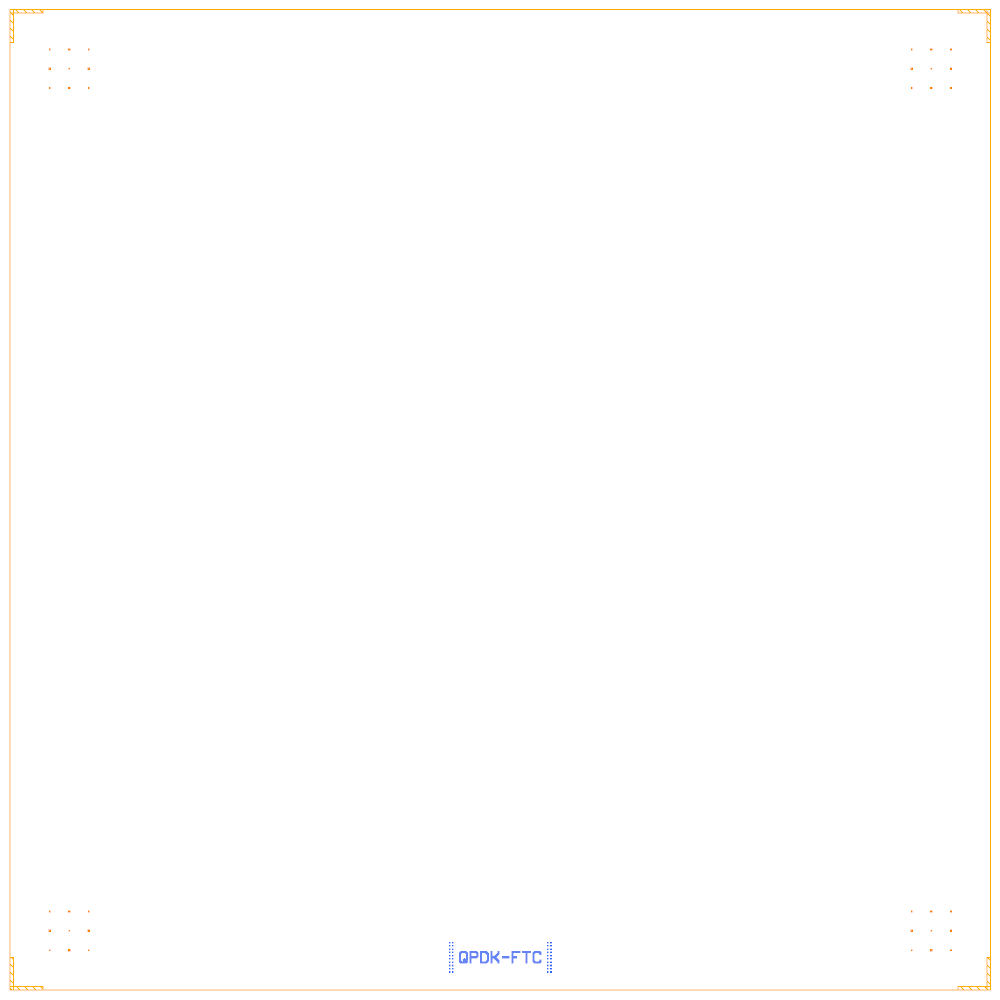

In [4]:
d = Designer("flipmon_test_chip", box=QP.die_box(4250, 6200), chip={"name_chip": "QPDK-FTC"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(1000, 1000), width=400);

## 4 · Pads and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge`
(100 µm) from the die edge. `edge="auto"` in `d.add` applies it: the pad keeps its position along the
nearest die edge (the source's launcher axis) and slides perpendicular to it until its etch ends 100 µm from
the edge. The lead routes to the circuit simply get longer; nothing else moves. The table shows each pad's
distance after the rule (✓ = 100 µm).
Launchers as in the qubit test chip: probeline in / out on the west edge, flux top / bottom.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PAD_IN | `BondPad` | w | 100.0 | ✓ |
| PAD_OUT | `BondPad` | w | 100.0 | ✓ |
| PAD_FT | `BondPad` | n | 100.0 | ✓ |
| PAD_FB | `BondPad` | s | 100.0 | ✓ |

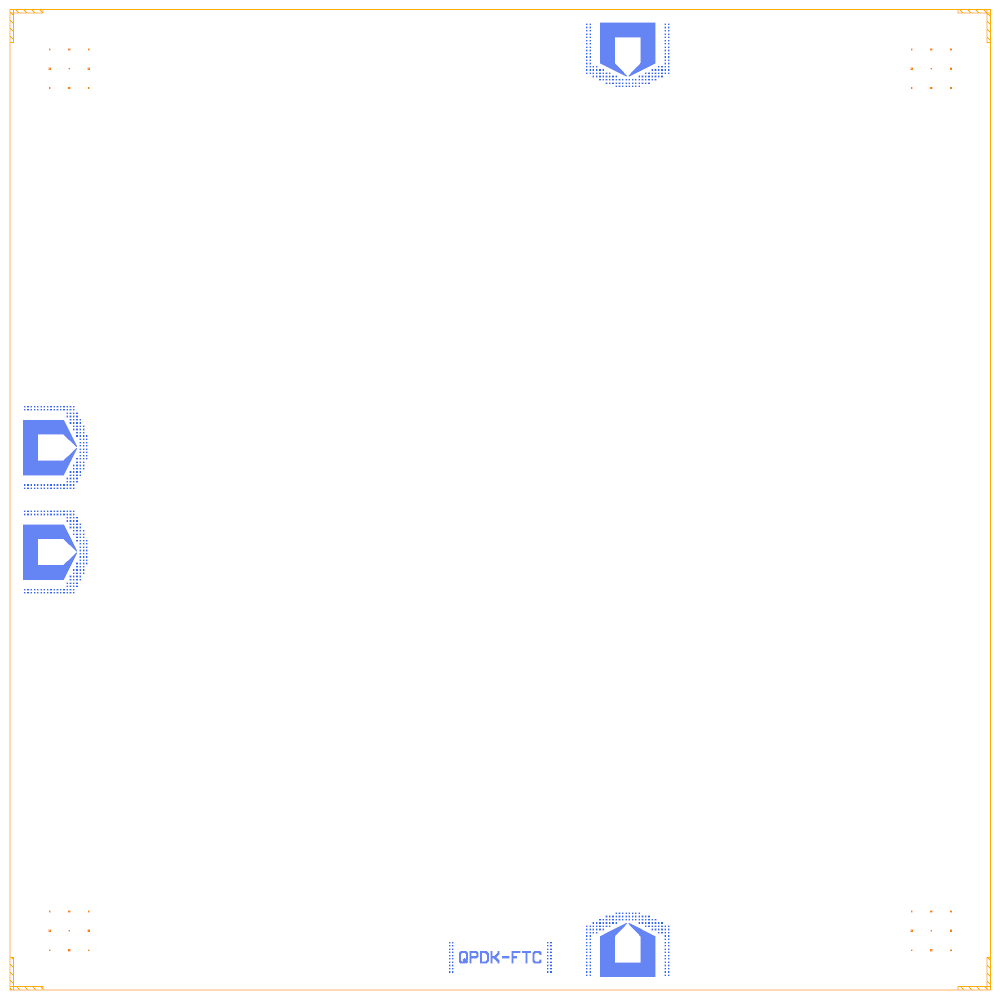

In [5]:
with d.batch():
    pin = d.add("PAD_IN", "BondPad", at=(DX + QP.LAUNCHER_DEPTH, DY + 400), rot=270, edge="auto", **QP.LAUNCHER)
    pout = d.add("PAD_OUT", "BondPad", at=(DX + QP.LAUNCHER_DEPTH, DY - 400), rot=270, edge="auto", **QP.LAUNCHER)
    pft = d.add("PAD_FT", "BondPad", at=(DX + 3000, 6200 - QP.LAUNCHER_DEPTH), rot=180, edge="auto", **QP.LAUNCHER)
    pfb = d.add("PAD_FB", "BondPad", at=(DX + 3000, QP.LAUNCHER_DEPTH), rot=0, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
snap(d, STEPS / "2_pads.png", size=(1000, 1000), width=400);

## 5 · Components

**Series IDCs** at the probeline input and output (`QP.IDC`). **Four flipmons** (`Flipmon`, QPDK defaults with
`junction_position_rotation=180`): Q1 / Q2 with the plate south (rotation 270), Q3 / Q4 mirrored in the source
→ plate north (rotation 90). Ports: `coupler` (the readout plate), `squid_a` / `squid_b` (junction reference
points on the disc and ring edges; the junction is drawn inside the cell).

<Flipmon Q1 ports=['coupler', 'squid_a', 'squid_b']>


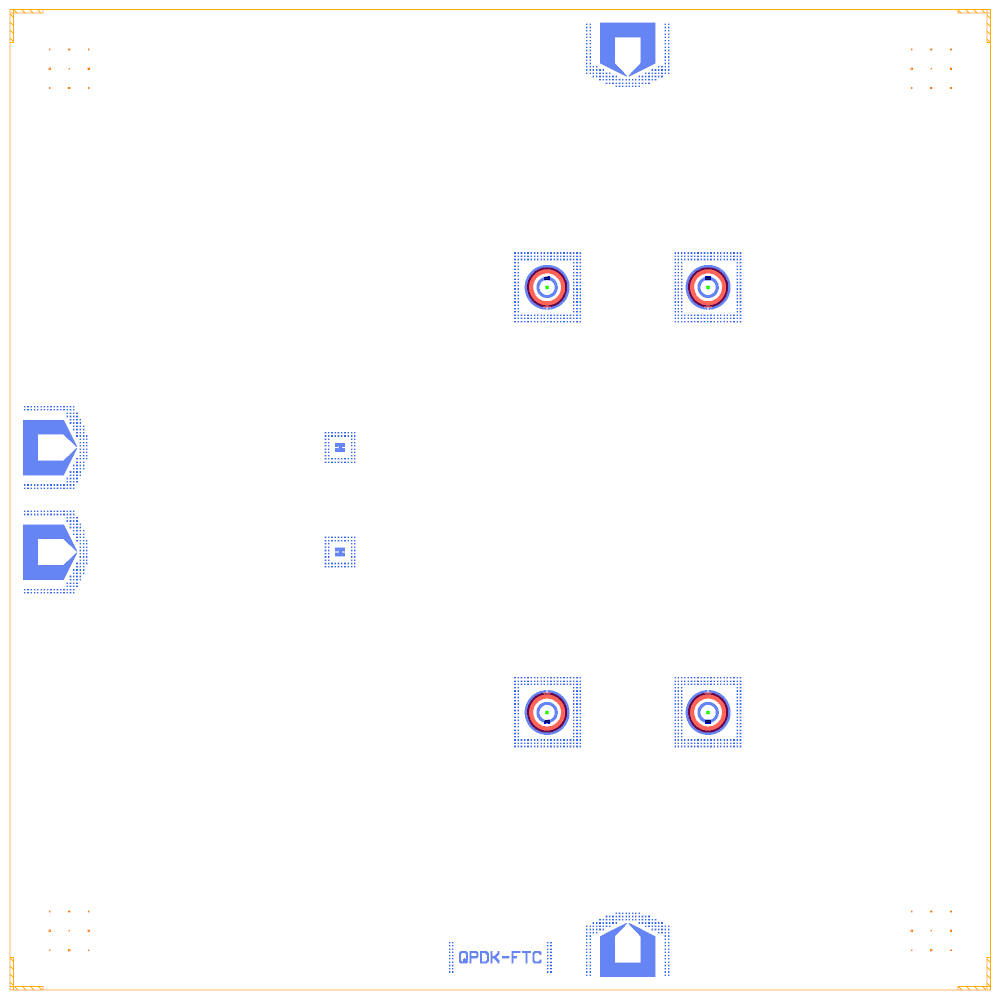

In [6]:
with d.batch():
    cin = d.add("C_IN", "FingerCapacitorSquare", at=(DX + 800, DY + 400), **QP.IDC)
    cout = d.add("C_OUT", "FingerCapacitorSquare", at=(DX + 800, DY - 400), **QP.IDC)
    q = {n: d.add(n, "Flipmon", at=(DX + x, DY + y), rot=r, junction=JJ, **JJ_PARAMS, **FM)
         for n, x, y, r in (("Q1", 2385, 1625, 270), ("Q2", 3615, 1625, 270),
                            ("Q3", 3615, -1627.421, 90), ("Q4", 2385, -1628.351, 90))}
print(q["Q1"])
snap(d, STEPS / "3_components.png", size=(1000, 1000), width=400);

## 6 · Routes

**Probeline:** launcher → C_IN → east, U-turn at x = 3815 µm (source), west → C_OUT → launcher (r = 100 µm).
**Readouts:** from each flipmon's plate, 900 µm west, a 7-turn meander (r = 50 µm), then the 800 µm coupled
section centred 500 µm west of the qubit, hanging on the probeline (`fl.hanger(s=..., length=800,
ground_gap=4, end="open")`: `s` is the arclength from the probeline's start at C_IN; open end → λ/2). Each route
is QPDK's length − 13 µm (`PORT_EXTRA`). **Flux lines** from the top / bottom launchers to an open end between
the qubit pairs.

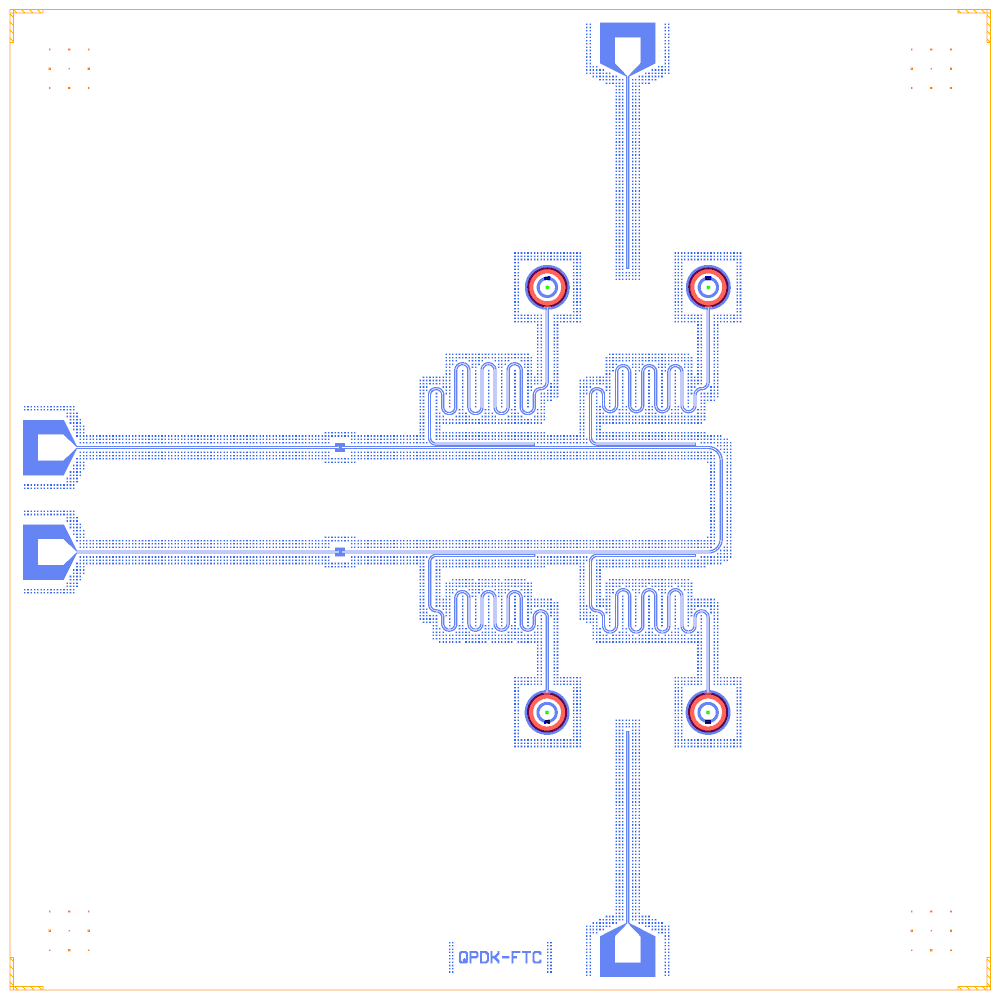

{'FL_IN': 1978.5, 'FL': 6471.2, 'FL_OUT': 1978.5, 'R1': 4987.0, 'R2': 4787.0, 'R3': 4587.0, 'R4': 4387.0, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}


In [7]:
with d.batch():
    d.route("FL_IN", pin.a, cin.a, r=QP.CPW_R)
    fl = d.route("FL", cin.b, cout.b, nodes=[(3815, DY + 400), (3815, DY - 400)], r=QP.CPW_R)
    d.route("FL_OUT", cout.a, pout.a, r=QP.CPW_R)
    x0 = 936.5                                         # FL starts at C_IN.b
    west = (3815 - x0) + 800                           # FL arclength at the start of the west-bound leg
    for n, qn, total, y in (("R1", "Q1", 5000, 3950), ("R2", "Q2", 4800, 3950), ("R3", "Q3", 4600, 2250),
                            ("R4", "Q4", 4400, 2250)):
        xq = d.data["instances"][qn]["place"]["at"][0]
        xc = xq - 500                                  # coupled-section centre
        top = y > DY
        s = xc - x0 if top else west + 3815 - xc
        d.route(n, q[qn].coupler, fl.hanger(s=s, length=800, side="left", ground_gap=QP.HANGER_GROUND_GAP,
                                            direction="forward" if top else "backward", end="open"),
                meander=total - PORT_EXTRA, r=50, nodes=[(xq, y), (xq - 900, y)]).set(meanders=7)
    d.route("FLUX_T", pft.a, Designer.free_end((DX + 3000, DY + 1775), dir=90, term=6), r=QP.CPW_R)
    d.route("FLUX_B", pfb.a, Designer.free_end((DX + 3000, DY - 1775), dir=270, term=6), r=QP.CPW_R)
snap(d, STEPS / "4_routes.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

**Centring.** `pdk_report` measures the content centre over everything placed, pads included, so the whole layout is
centred, not only the circuit. The probeline pads sit 100 µm (`frame.pad_edge`) from the west die edge
(`edge="auto"`), which fixes the west side of the content, so `QP.center_content` shifts the circuit east until the
content box's centre is the die centre (to 0.5 µm). Each pad keeps its 100 µm and slides only along its edge: the
west pads follow the shift in y, the top / bottom flux pads in x (their edge is fixed first, so a pad that slides far
along an edge does not switch to another one). Here the circuit moves **+1890 µm** in x from the source frame (the circuit-only centring
of earlier versions stopped 2139 µm short of that). The circuit's east side (the Q2 / Q3 pockets) then sits exactly on the
design-area margin, 100 µm from the east die edge: the DRC raises no `frame_margin` / `frame_keepout` warning and the
PDK cheese band still fits (its holes stop 10 µm inside the margin). The price: the probeline leads from the pads to
the IDCs are 3868.5 µm long (were 1729.3 µm); the readouts, the probeline and the qubits are unchanged, and so is the LOM (the
leads are outside the sim groups). Then the design is saved: the JSON is what DRC, LOM, FEM and `qcc` read.
**Sim groups:** one per qubit with its readout and the probeline (Q3D C-matrix + eigenmode/EPR, 150 µm margin).

In [8]:
for i in range(1, 5):
    d.sim_group(f"Q{i}R{i}", [f"Q{i}", f"R{i}", "FL"], margin_um=150)
SHIFT = QP.center_content(d)                  # the whole layout (pads included) centred, pads stay on their edges
print("centring shift of the circuit (µm):", SHIFT)
rebuild(d)
print("lead lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items() if k in ("FL_IN", "FL_OUT", "FLUX_T", "FLUX_B")})
DESIGN = d.save(OUT / "flipmon_test_chip.json")
print(d, "→", DESIGN)

centring shift of the circuit (µm): (1890.0, 0.0)


lead lengths (µm): {'FL_IN': 3868.5, 'FL_OUT': 3868.5, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}
<Designer flipmon_test_chip: 10 instances, 9 routes, live=False> → examples\designs\qpdk\flipmon_test_chip.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included: it reads (+0, +0) µm after step 6's `QP.center_content`)
and the junction types.
Here: eight `dangling_port` warnings (the `Flipmon` `squid_a` / `squid_b` reference points; the junction is drawn
inside the cell) and no PDK design warning (SQUID R_n 45 kΩ — the parallel R_n of its two junctions — inside
the window; pads at 100 µm).

In [9]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 8 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 8 | Q1.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 4 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
The `Flipmon` model: the inner disc + the top-chip disc form one island node, the ring is a second node, the
SQUID joins them, both have C to ground, and the plate is a coupler node. Each readout is a λ/2 `TLres` from the
plate node with a `HANGER` κ element to the probeline node.

In [10]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('Q1.', 'R1',)))))

**18 nodes · 52 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `C_IN.a` | `PAD_IN.pad`, `C_IN.a` |
| `C_OUT.a` | `PAD_OUT.pad`, `C_OUT.a` |
| `PAD_FT.pad` | `PAD_FT.pad` |
| `PAD_FB.pad` | `PAD_FB.pad` |
| `C_IN.b` | `C_IN.b`, `C_OUT.b` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.cplr` | `Q1.cplr` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.cplr` | `Q2.cplr` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.cplr` | `Q3.cplr` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.cplr` | `Q4.cplr` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_IN` | R | `C_IN.a` – `gnd` | 50 Ω |
| `Port_PAD_OUT` | R | `C_OUT.a` – `gnd` | 50 Ω |
| `Port_PAD_FT` | R | `PAD_FT.pad` – `gnd` | 50 Ω |
| `Port_PAD_FB` | R | `PAD_FB.pad` – `gnd` | 50 Ω |
| `C_C_IN` | C | `C_IN.a` – `C_IN.b` | 6.12 fF |
| `C_C_IN_a` | C | `C_IN.a` – `gnd` | 2.7 fF |
| `C_C_IN_b` | C | `C_IN.b` – `gnd` | 2.7 fF |
| `C_C_OUT` | C | `C_OUT.a` – `C_IN.b` | 6.12 fF |
| `C_C_OUT_a` | C | `C_OUT.a` – `gnd` | 2.7 fF |
| `C_C_OUT_b` | C | `C_IN.b` – `gnd` | 2.7 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 83.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 46 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 5.1 fF |
| `C_Q1_12_flip` | C | `Q1.island1` – `Q1.island2` | 20 fF |
| `C_Q1_2_top` | C | `Q1.island2` – `gnd` | 71 fF |
| `J_Q1` | SQUID | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_cplr` | C | `Q1.island1` – `Q1.cplr` | 6.43 fF |
| `Cc_Q1_cplr` | C | `Q1.cplr` – `gnd` | 7.4 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 83.3 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 46 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 5.1 fF |
| `C_Q2_12_flip` | C | `Q2.island1` – `Q2.island2` | 20 fF |
| `C_Q2_2_top` | C | `Q2.island2` – `gnd` | 71 fF |
| `J_Q2` | SQUID | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_cplr` | C | `Q2.island1` – `Q2.cplr` | 6.43 fF |
| `Cc_Q2_cplr` | C | `Q2.cplr` – `gnd` | 7.4 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 83.3 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 46 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 5.1 fF |
| `C_Q3_12_flip` | C | `Q3.island1` – `Q3.island2` | 20 fF |
| `C_Q3_2_top` | C | `Q3.island2` – `gnd` | 71 fF |
| `J_Q3` | SQUID | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_cplr` | C | `Q3.island1` – `Q3.cplr` | 6.43 fF |
| `Cc_Q3_cplr` | C | `Q3.cplr` – `gnd` | 7.4 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 83.3 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 46 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 5.1 fF |
| `C_Q4_12_flip` | C | `Q4.island1` – `Q4.island2` | 20 fF |
| `C_Q4_2_top` | C | `Q4.island2` – `gnd` | 71 fF |
| `J_Q4` | SQUID | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_cplr` | C | `Q4.island1` – `Q4.cplr` | 6.43 fF |
| `Cc_Q4_cplr` | C | `Q4.cplr` – `gnd` | 7.4 fF |
| `R1` | TLres | `Q1.cplr` – `gnd` | lambda/2, 4987 µm, 12.636 GHz |
| `K_R1` | HANGER | `Q1.cplr` – `C_IN.b` | κ 0.82 MHz (L 800 µm) |
| `R2` | TLres | `Q2.cplr` – `gnd` | lambda/2, 4787 µm, 13.164 GHz |
| `K_R2` | HANGER | `Q2.cplr` – `C_IN.b` | κ 0.925 MHz (L 800 µm) |
| `R3` | TLres | `Q3.cplr` – `gnd` | lambda/2, 4587 µm, 13.738 GHz |
| `K_R3` | HANGER | `Q3.cplr` – `C_IN.b` | κ 1.05 MHz (L 800 µm) |
| `R4` | TLres | `Q4.cplr` – `gnd` | lambda/2, 4387 µm, 14.365 GHz |
| `K_R4` | HANGER | `Q4.cplr` – `C_IN.b` | κ 1.2 MHz (L 800 µm) |
| `FLUX_T` | TLres | `PAD_FT.pad` – `gnd` | lambda/2, 1465 µm, 43.015 GHz |
| `FLUX_B` | TLres | `PAD_FB.pad` – `gnd` | lambda/2, 1465 µm, 43.015 GHz |

**Unconnected ports:** none

**Builder notes:**

- Q1: M2 top disc (face 2b1) counted in island2 across an assumed 8 µm flip-chip gap (rough; PDK v2 does not fabricate face 2b1); coupler ↔ disc C neglected (screened by the ring)
- Q2: M2 top disc (face 2b1) counted in island2 across an assumed 8 µm flip-chip gap (rough; PDK v2 does not fabricate face 2b1); coupler ↔ disc C neglected (screened by the ring)
- Q3: M2 top disc (face 2b1) counted in island2 across an assumed 8 µm flip-chip gap (rough; PDK v2 does not fabricate face 2b1); coupler ↔ disc C neglected (screened by the ring)
- Q4: M2 top disc (face 2b1) counted in island2 across an assumed 8 µm flip-chip gap (rough; PDK v2 does not fabricate face 2b1); coupler ↔ disc C neglected (screened by the ring)

**Ports → circuit nodes:**

| port | node |
|---|---|
| `Q1.coupler` | `Q1.cplr` |
| `Q1.squid_a` | `Q1.island2` |
| `Q1.squid_b` | `Q1.island1` |

## 9 · LOM simulation

Each group holds one qubit, its λ/2 readout and the probeline (QuCat normal modes and κ, then QuTiP f_q, α, f_r,
χ). The source states no targets; f_q follows from the PDK SQUID and the rough flip-chip capacitance (assumed
8 µm gap): ≈ 5.4 GHz expected (the earlier 12 nH stand-in gave 4.2 GHz).

In [11]:
groups = {f"Q{i}R{i}": [f"Q{i}", f"R{i}", "FL"] for i in range(1, 5)}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1R1 | Q1 | 5.3849 | -170.3 | R1 | 12.349 | 0.748 | -0.0434 |
| Q2R2 | Q2 | 5.3849 | -170.3 | R2 | 12.852 | 0.841 | -0.0425 |
| Q3R3 | Q3 | 5.3849 | -170.3 | R3 | 13.399 | 0.95 | -0.042 |
| Q4R4 | Q4 | 5.3849 | -170.3 | R4 | 13.995 | 1.08 | -0.0429 |

## 10 · FEM: send the jobs
Per qubit / readout pair a Q3D C-matrix job and an eigenmode / EPR job. **Known export limits** (reported to
components / lead, not fixed here): KQC finds no metal edge at the `Flipmon` junction port (its reference points
land inside the 60–80 µm disc–ring gap), logs "Unable to create polygon for port 1" and puts the disc and the ring
on one excitation, so the C-matrix has no separate ring net; the stack is single-face, so the top-chip disc
(face 2b1) is not in the job. Treat these jobs as geometry exports, not as a flip-chip C-matrix.
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs`
solves each Ansys job in a **new batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open
is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [12]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

8 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 · eigenmode_epr | `build/jobs/flipmon_test_chip_Q1R1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `FLUX_T`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R3`<br>6 · edge_lumped · `R4` | `Q1.island2`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `Q1.cplr`, `R2`, `Q1.island1`, `floating` |
| Q1R1 · q3d_cmatrix | `build/jobs/flipmon_test_chip_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.coupler`<br>3 · edge · `FLUX_T`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R3`<br>7 · edge · `R4` | `Q1.island2`, `Q1.coupler`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `R2`, `Q1.island1`, `floating` |
| Q2R2 · eigenmode_epr | `build/jobs/flipmon_test_chip_Q2R2_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `FLUX_T`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R3`<br>6 · edge_lumped · `R4` | `Q2.island2`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `R1`, `Q2.cplr`, `floating`, `Q2.island1` |
| Q2R2 · q3d_cmatrix | `build/jobs/flipmon_test_chip_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.coupler`<br>3 · edge · `FLUX_T`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R3`<br>7 · edge · `R4` | `Q2.island2`, `Q2.coupler`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `R1`, `floating`, `Q2.island1` |
| Q3R3 · eigenmode_epr | `build/jobs/flipmon_test_chip_Q3R3_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `FLUX_B`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R1`<br>6 · edge_lumped · `R2` | `Q3.island2`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `floating`, `Q3.island1`, `R4`, `Q3.cplr`, `FL` |
| Q3R3 · q3d_cmatrix | `build/jobs/flipmon_test_chip_Q3R3_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.coupler`<br>3 · edge · `FLUX_B`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R1`<br>7 · edge · `R2` | `Q3.island2`, `Q3.coupler`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `floating`, `Q3.island1`, `R4`, `FL` |
| Q4R4 · eigenmode_epr | `build/jobs/flipmon_test_chip_Q4R4_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · edge_lumped · `FLUX_B`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R1`<br>6 · edge_lumped · `R2` | `Q4.island2`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `Q4.island1`, `floating`, `Q4.cplr`, `R3`, `FL` |
| Q4R4 · q3d_cmatrix | `build/jobs/flipmon_test_chip_Q4R4_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.coupler`<br>3 · edge · `FLUX_B`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R1`<br>7 · edge · `R2` | `Q4.island2`, `Q4.coupler`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `Q4.island1`, `floating`, `R3`, `FL` |

## 11 · Bring the results back

A solved job holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`: the C-matrix
(or eigenmode) values replace the component estimates branch by branch, matched by net name, and the table
compares the two; `simulate(filled)` re-runs the LOM on the extracted values. Until then the cell says which
jobs are still waiting.

In [13]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for Q1R1 · eigenmode_epr, Q1R1 · q3d_cmatrix, Q2R2 · eigenmode_epr, Q2R2 · q3d_cmatrix, Q3R3 · eigenmode_epr, Q3R3 · q3d_cmatrix, Q4R4 · eigenmode_epr, Q4R4 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The junction is the qubit's main knob: size Q1's SQUID for L_J = 9 nH instead of 6.73 nH (narrower fingers,
R_n ≈ 60 kΩ in parallel — outside the PDK window, so `pdk_rn` would flag it). f_q drops roughly as
1/√L_J (≈ −14 %) and |α| barely moves. Done on a copy (`design_copy`), so the design keeps the PDK nominal SQUID.

In [14]:
JJ_PARAMS_9, JJ_9 = QP.trilayer_junction("Flipmon", lj_nH=9.0, squid=True)
d2 = design_copy(DESIGN)
d2["Q1"].set(junction=JJ_9, **JJ_PARAMS_9)
after = simulate_groups(d2, {"Q1R1": groups["Q1R1"]})
display(Markdown("**Q1 SQUID: L_J 6.73 → 9 nH**\n\n" + params_delta_md({"Q1R1": res["Q1R1"]}, after)))

**Q1 SQUID: L_J 6.73 → 9 nH**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1R1: Q1.f_q_GHz` | 5.3849 | 4.7405 | -0.6444 |
| `Q1R1: Q1.alpha_MHz` | -170.27 | -177.82 | -7.546 |
| `Q1R1: R1.chi_MHz` | -0.043397 | -0.043344 | +5.261e-05 |
| `Q1R1: R1.f_GHz` | 12.349 | 12.349 | -3.165e-05 |
| `Q1R1: R1.kappa_MHz` | 0.74759 | 0.74759 | +4.097e-06 |

## 13 · Build and export

**The design file.** `flipmon_test_chip.json` (saved in step 6) is the whole design: `qcc build
examples/designs/qpdk/flipmon_test_chip.json` rebuilds `build/flipmon_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
The flip-chip top face exports to 800/0 (etch), 801/0 (indium bump) and 802/0 (UBM). The cheese source is
`build`: the PDK band on the bottom chip (the source has none), at least 4 µm clear of 3/0.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/flipmon_test_chip.json`
writes the complete file.

In [15]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 7612 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 7599 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 16 |
| 51/0 | SPACER_1 | 16 |
| 52/0 | SPACER_2 | 16 |
| 53/0 | SPACER_3 | 16 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 800/0 | FC_M1 | 4 |
| 801/0 | FC_BUMPS | 4 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 7593 holes on the mask.

→ `build/flipmon_test_chip_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [16]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped', 'indium_bump_shapes': 4, 'vertex_contacts_joined': 1} indium bumps dropped (4 shapes): the simulation has one face (1t1), so a bump would be a PEC pillar to the top of the box; the flip-chip top face (2b1) is not simulated 1 metal piece(s) touching at a single point joined with a 0.5 µm patch at (5605.0, 4785.0) µm: KQC counts a point contact as connected, Q3D does not ("objects … are touching") 2 conductor(s) no port or LOM node touches, named after their component: R2, floating (cut where dropped airbridges crossed, floating parts of a cell, or ground enclosed by it; airbridges=True keeps the bridges)


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept', 'indium_bump_shapes': 4, 'vertex_contacts_joined': 1} indium bumps dropped (4 shapes): the simulation has one face (1t1), so a bump would be a PEC pillar to the top of the box; the flip-chip top face (2b1) is not simulated 1 metal piece(s) touching at a single point joined with a 0.5 µm patch at (5605.0, 4785.0) µm: KQC counts a point contact as connected, Q3D does not ("objects … are touching") 2 conductor(s) no port or LOM node touches, named after their component: R2, floating (cut where dropped airbridges crossed, floating parts of a cell, or ground enclosed by it; airbridges=True keeps the bridges)


## 14 · Snapshots

The full die (QPDK's render of the *filled* flipmon variant is shown last); qubit Q1 with its readout plate (both
faces); its junction; the R1 coupled section's open end; the top flux-line end; the die frame's south-west
corner; and Q1 in the **fab view** (the mask from step 13: 1/0 with the PDK cheese band, 3/0, the trilayer
layers, the 800/0 face). Boxes are the source positions + the centring shift. (Layout snapshots: the chip
boundary 100/0 is drawn as an outline and the cheese band is visible; the fab view shows the mask itself.)

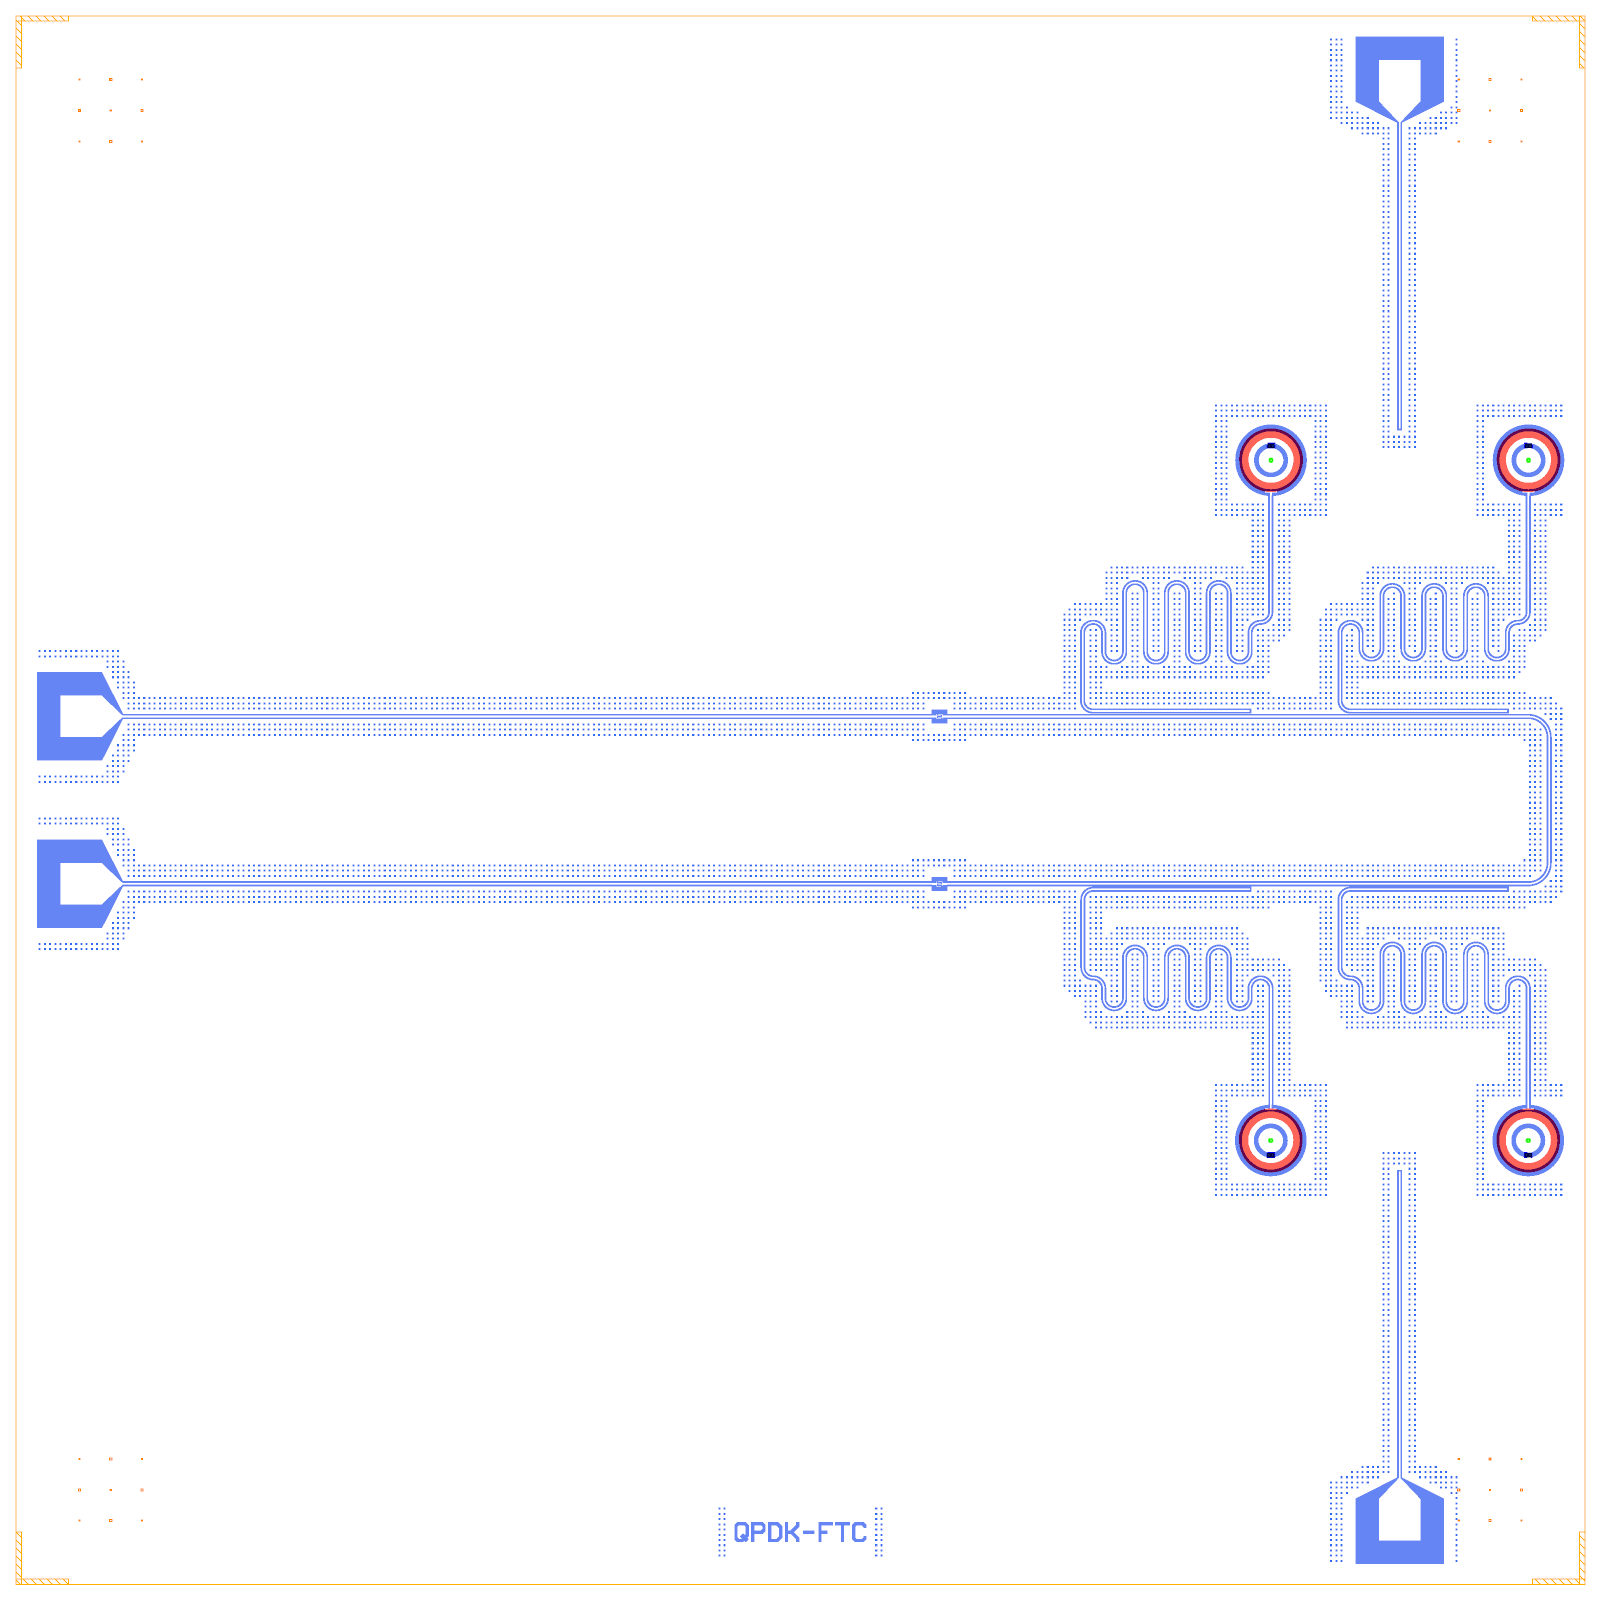

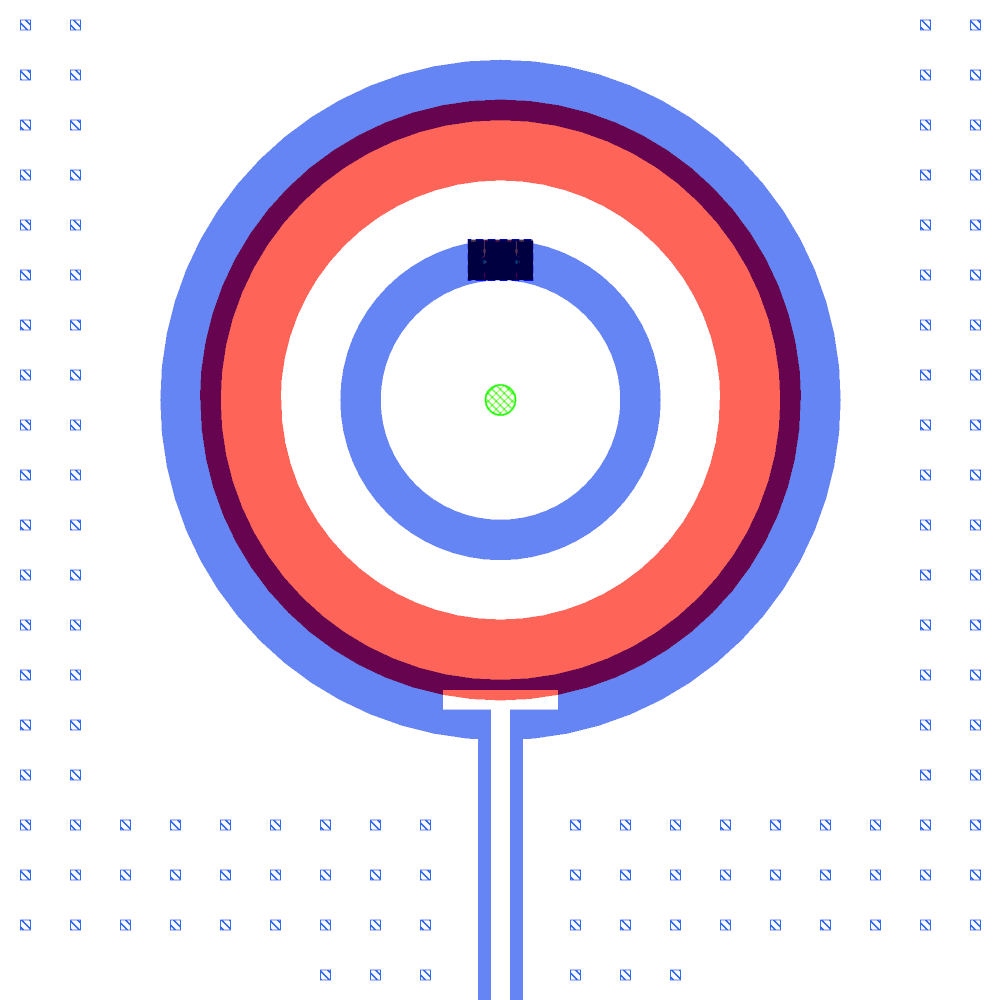

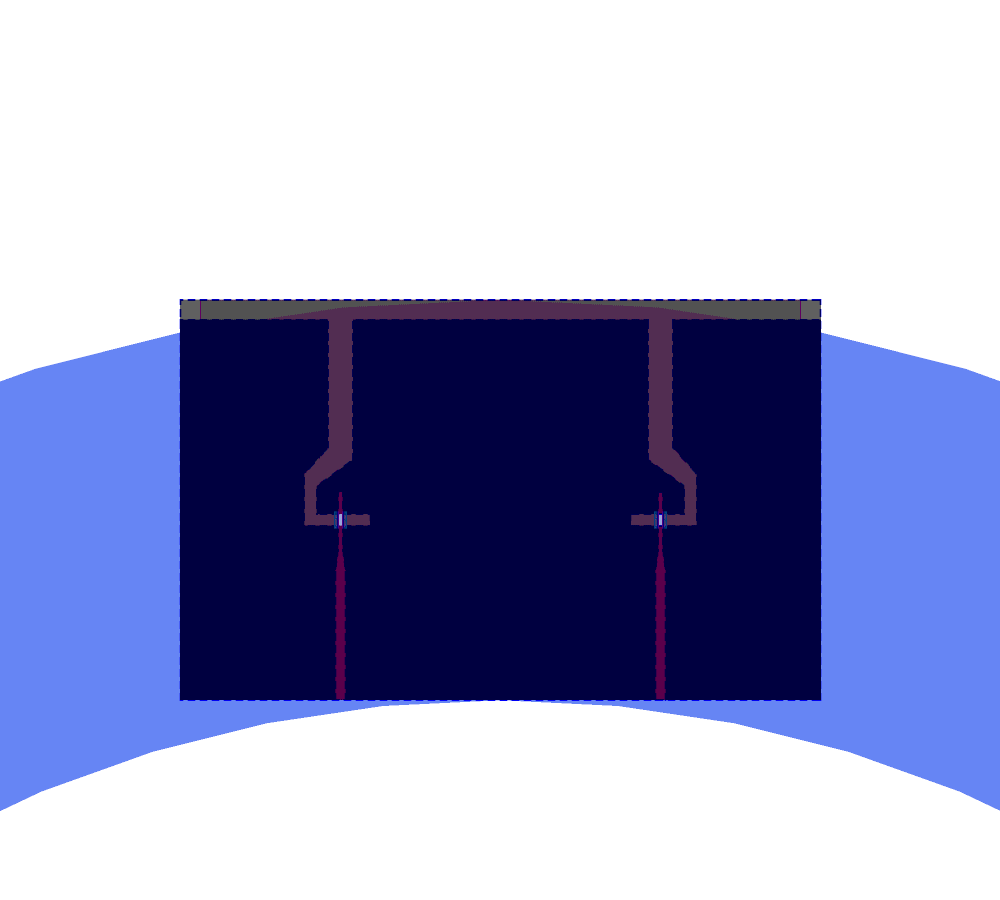

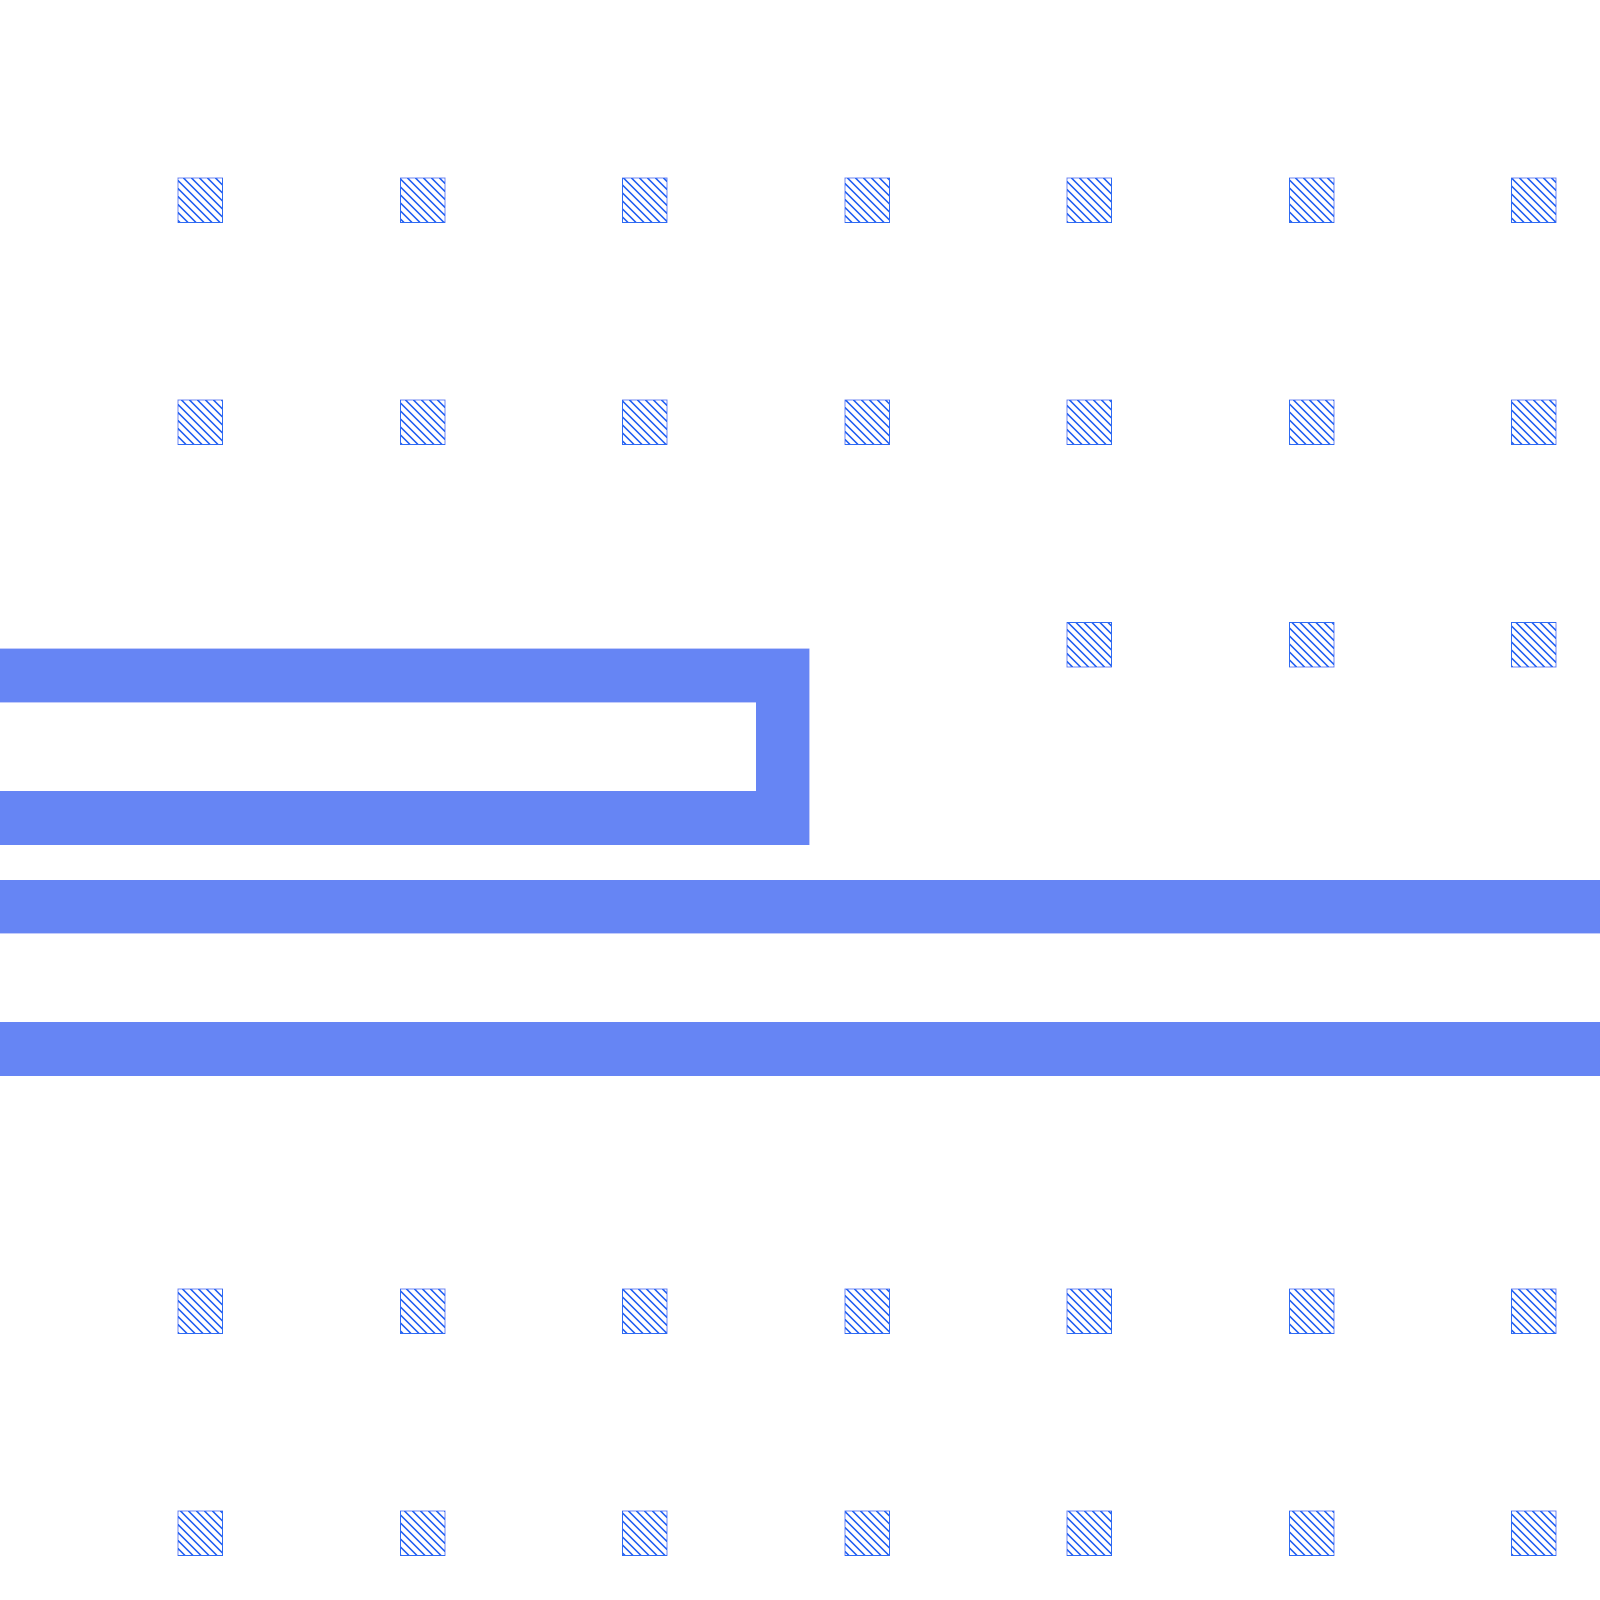

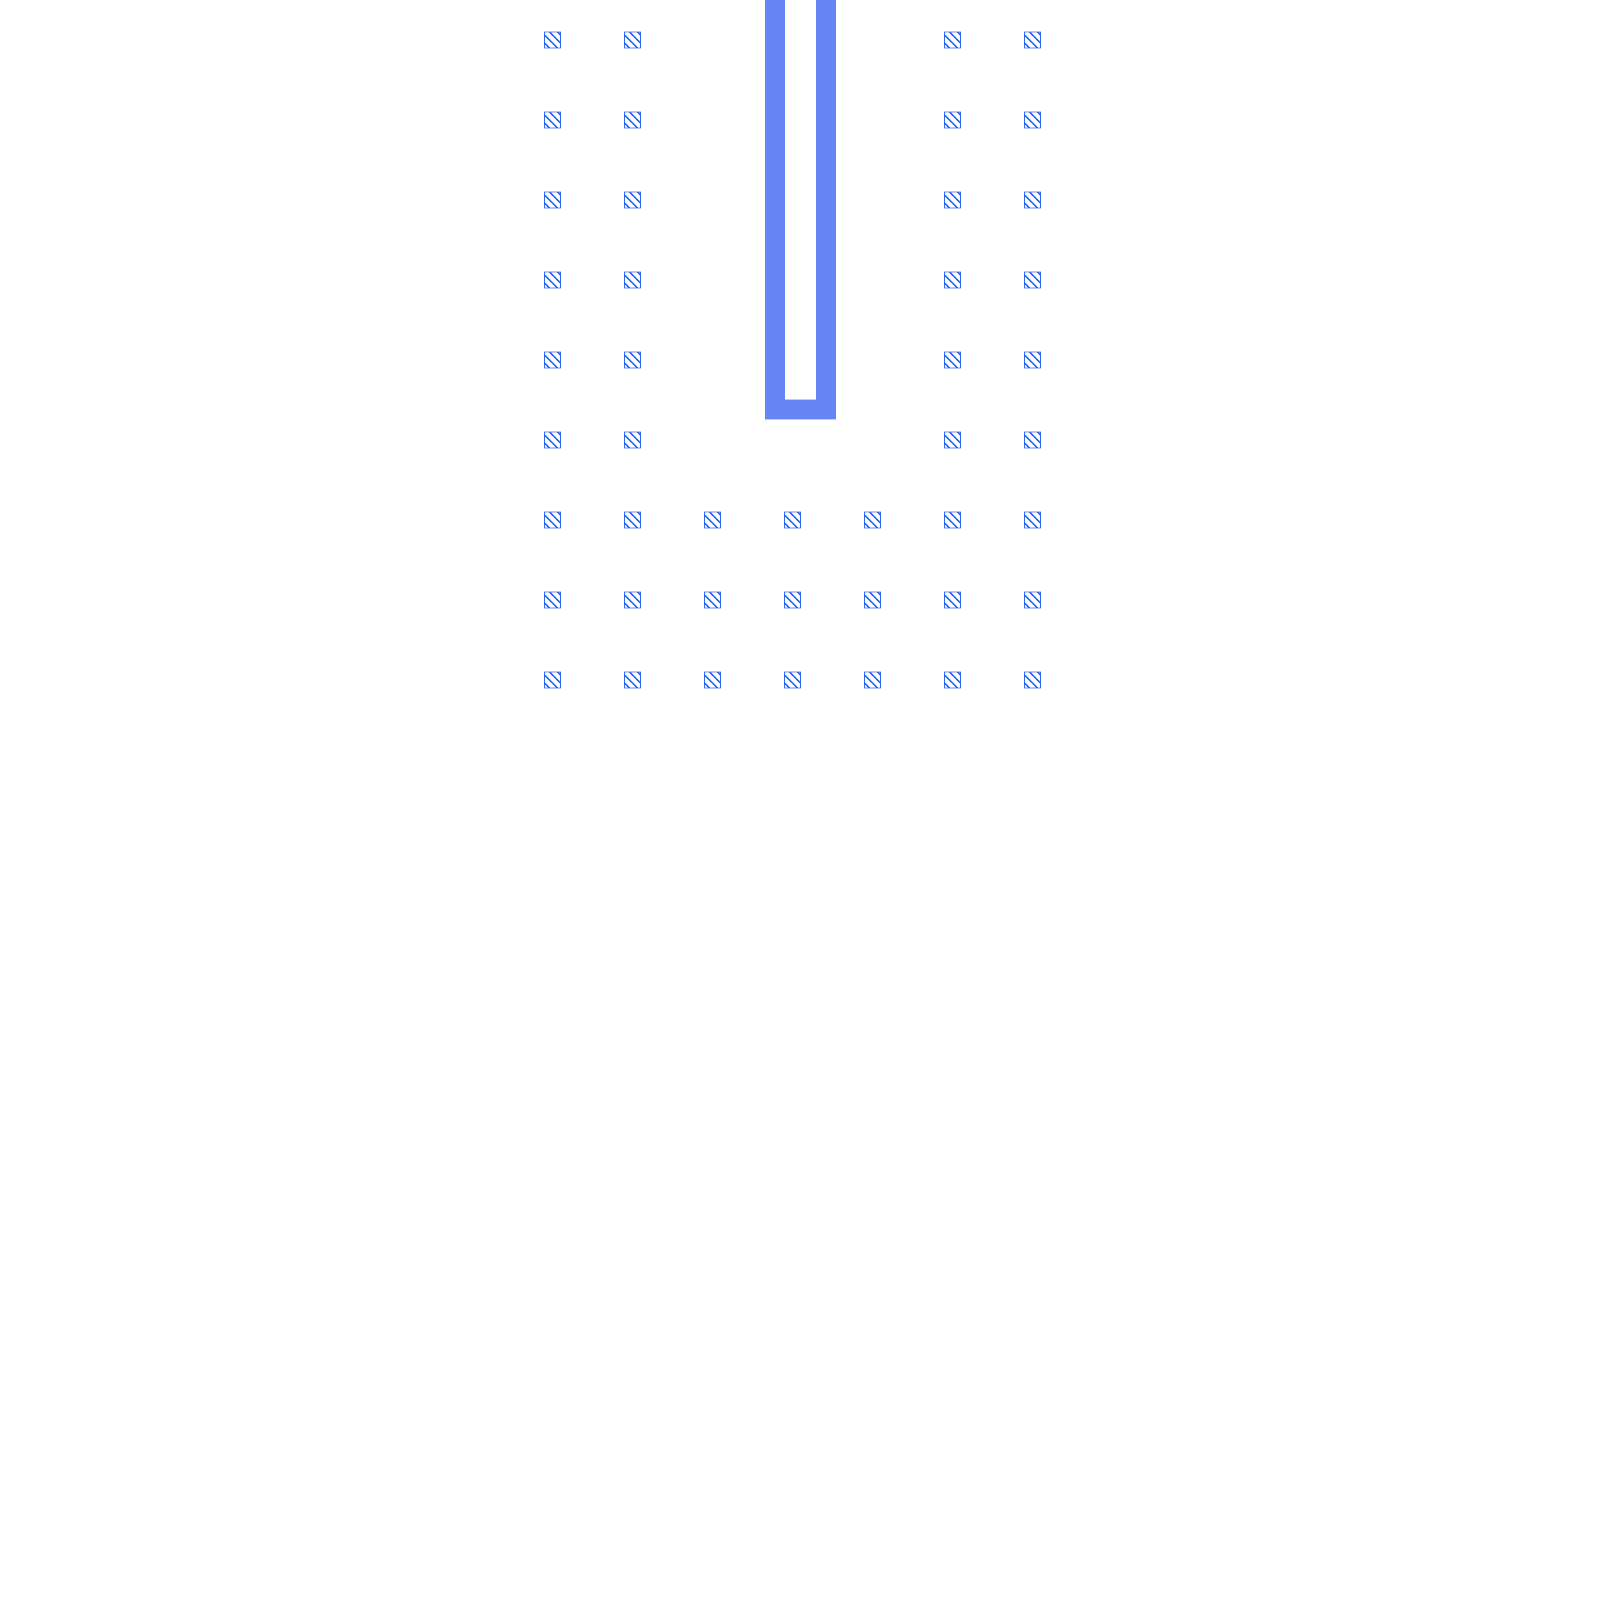

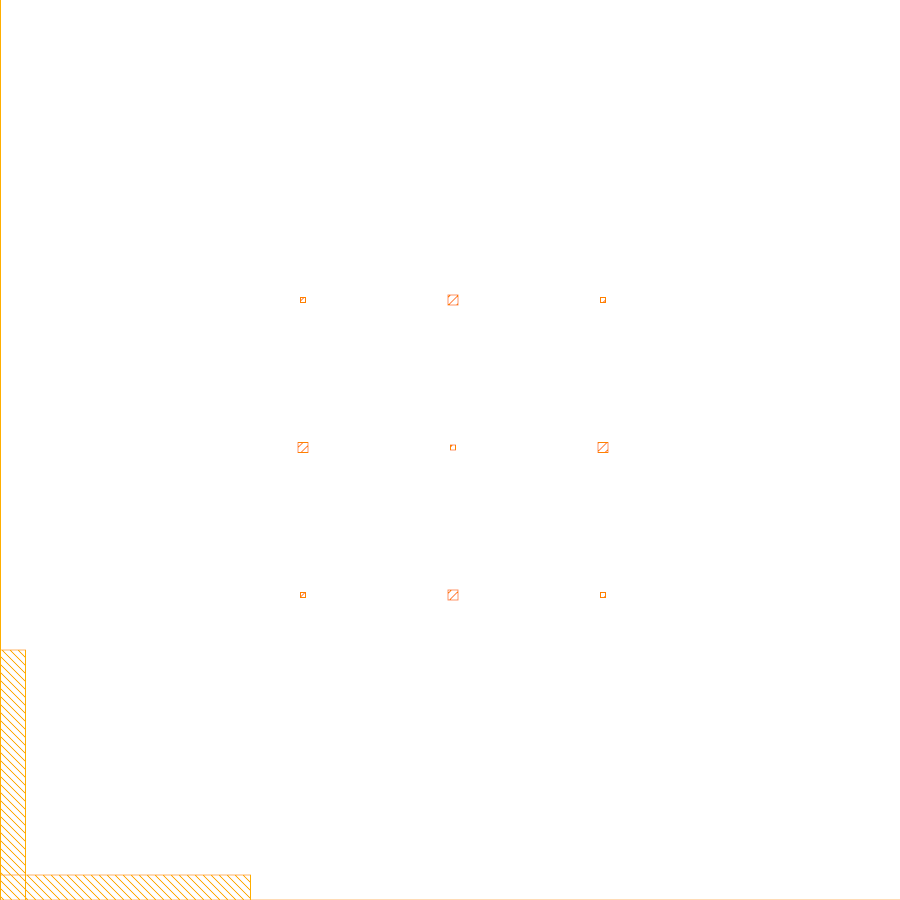

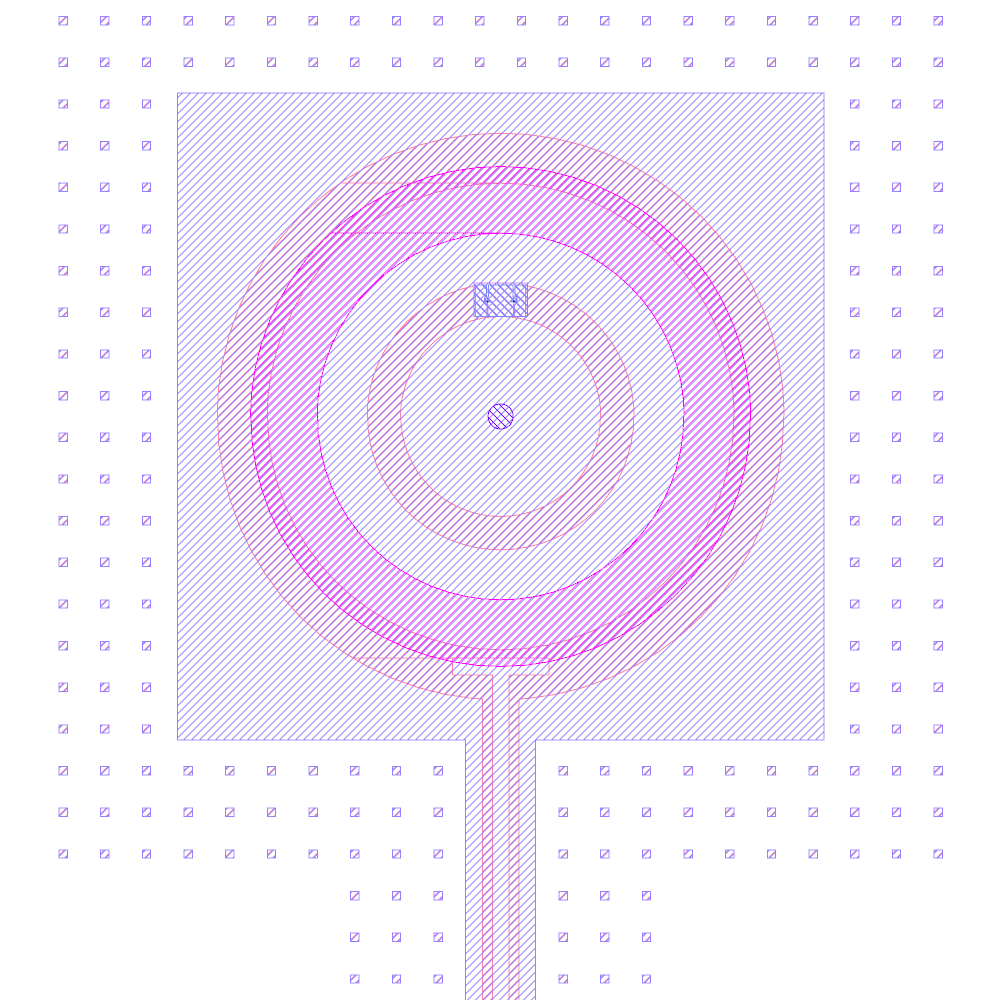

In [17]:
SX, SY = SHIFT


def box(x0, y0, x1, y1):                         # a source-frame box, moved with the centring shift
    return (x0 + SX, y0 + SY, x1 + SX, y1 + SY)


show_snapshot(d, OUT / "flipmon_test_chip.png", size=(1600, 1600))
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "flipmon_test_chip_q1.png", box=(qx - 250, qy - 300, qx + 250, qy + 200), size=(1000, 1000), width=400)
show_snapshot(d, OUT / "flipmon_test_chip_squid.png", box=(qx - 25, qy + 50, qx + 25, qy + 95), size=(1000, 900), width=300)
show_snapshot(d, OUT / "flipmon_test_chip_coupler.png", box=box(2300, 3440, 2480, 3600), width=360)
show_snapshot(d, OUT / "flipmon_test_chip_flux.png", box=box(2900, 4500, 3300, 5000), width=360)
show_snapshot(d, OUT / "flipmon_test_chip_frame.png", box=(-1625, -650, -725, 250), size=(900, 900), width=300)
snap_file(Path("build") / "flipmon_test_chip_fab.oas", OUT / "flipmon_test_chip_fab_q1.png",
          box=(qx - 300, qy - 350, qx + 300, qy + 250), size=(1000, 1000), width=400);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render (of the filled flipmon variant, the only image QPDK publishes for this chip) is shown from the local
clone when present.

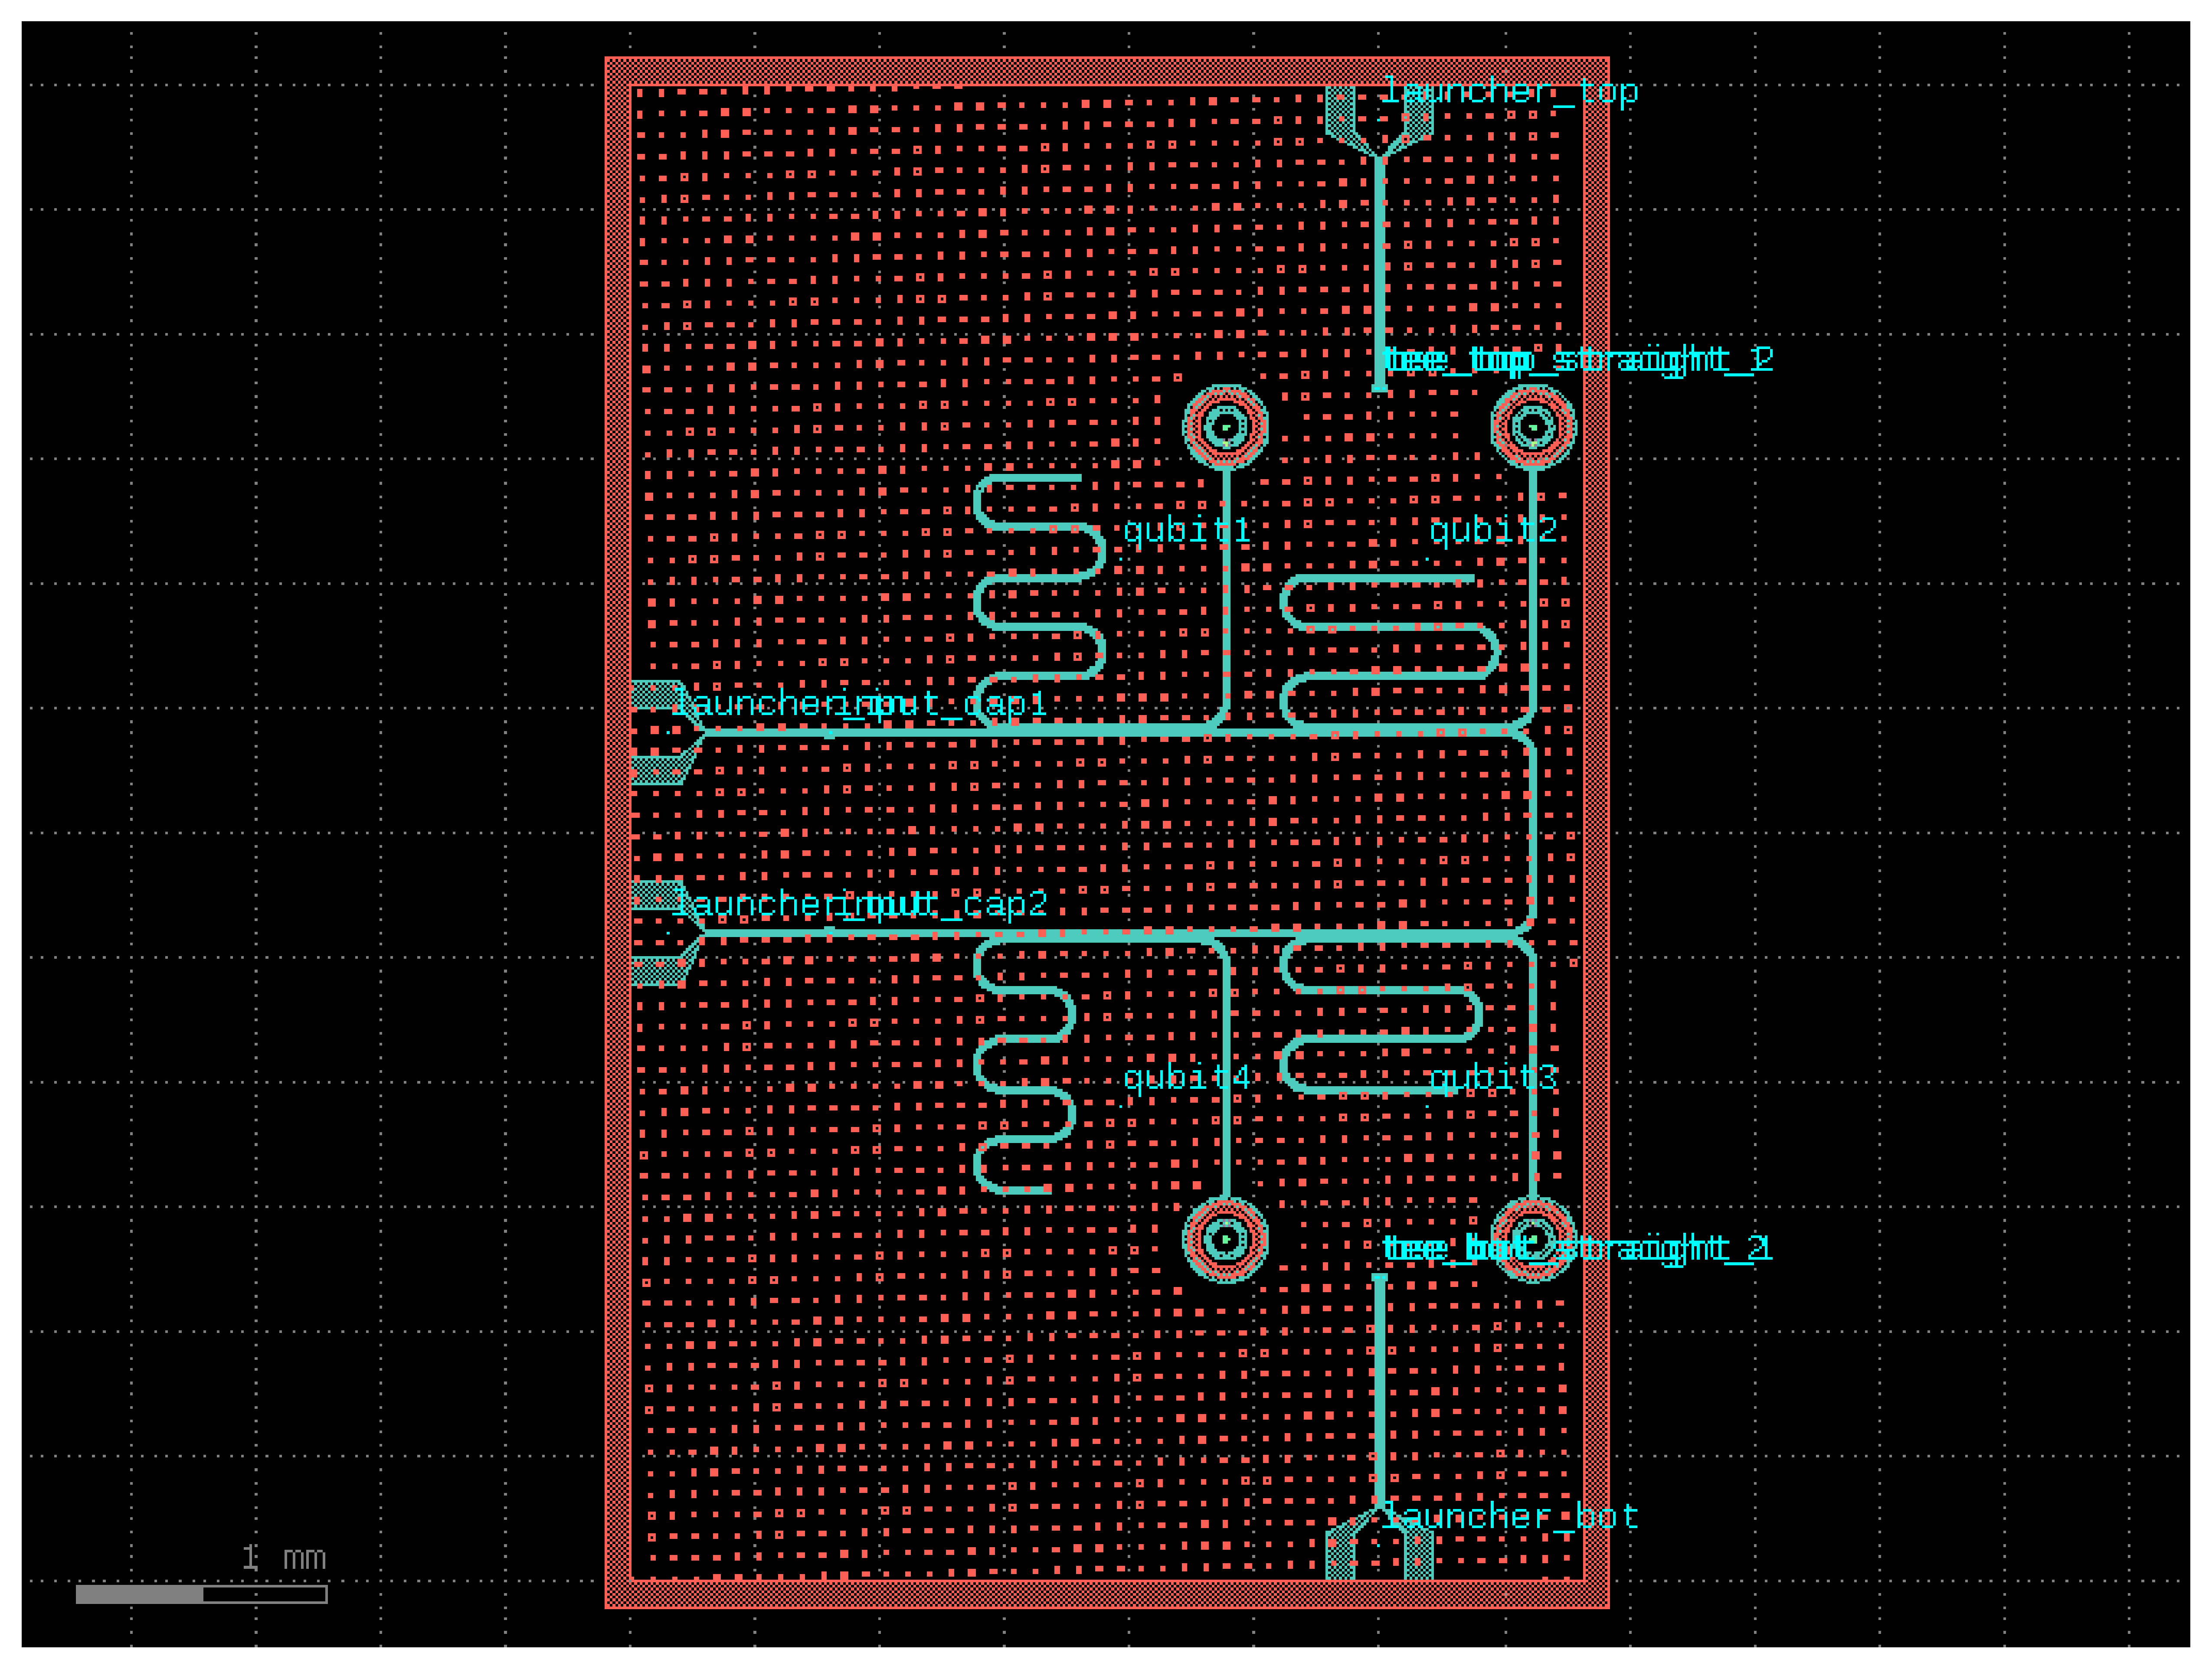

In [18]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "flipmon_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/flipmon_test_chip.png")

## 15 · Summary

| | |
|---|---|
| **matches the source** | the qubit test chip's netlist with QPDK's flipmon (both faces, bump, plate), readout lengths 5000–4400 µm with 800 µm coupled sections (λ/2, open), the U-turn at 3815 µm, IDCs, flux lines, launcher size |
| **differs (PDK)** | 7.5 mm Quantcore die and frame (bottom chip only); pads 100 µm from the die edge; the whole layout centred (circuit +1890 µm in x, pads included; probeline leads 3869 µm, the circuit's east side 100 µm from the east die edge); sapphire; trilayer SQUIDs across the disc–ring gap (f_q ≈ 5.4 GHz); the PDK cheese band |
| **estimated** | the flip-chip capacitance (assumed 8 µm gap); the FEM jobs are single-face geometry exports |
| **PDK design warnings** | none |
| **FEM** | 8 jobs (4 × Q3D, 4 × eigenmode/EPR) exported to `build/jobs/flipmon_test_chip_*`, not solved here |